In [19]:
import pyspark

print("PySpark is installed.")
print("PySpark version:", pyspark.__version__)

PySpark is installed.
PySpark version: 4.2.0


In [20]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("PySpark Installation Check")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

spark.range(5).show()

spark.stop()

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark version: 4.2.0
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [21]:
import pandas as pd
import pyspark
import sys

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("PySpark version:", pyspark.__version__)

Python version: 3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
Pandas version: 3.0.5
PySpark version: 4.2.0


In [22]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("PySpark Installation Check")
    .master("local[*]")
    .getOrCreate()
)

print("Spark version:", spark.version)

spark.range(5).show()

Spark version: 4.2.0
+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



In [25]:
# ============================================================
# DIAGNOSTIC: CHECK PACKAGE VERSIONS
# ============================================================

import sys
import numpy as np
import scipy
import sklearn

print("Python executable:", sys.executable)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Scikit-learn version:", sklearn.__version__)

Python executable: C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\python.exe
NumPy version: 2.4.6
SciPy version: 1.17.1
Scikit-learn version: 1.9.0


In [1]:
# ============================================================
# TEST: SCIKIT-LEARN IMPORTS
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Scikit-learn imports successful!")

Scikit-learn imports successful!


In [2]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import NumericType

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    log_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.linear_model import LogisticRegression as ReferenceLogisticRegression

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [27]:
# ============================================================
# CELL 2: CREATE SPARK SESSION AND LOAD DATA
# ============================================================

spark = (
    SparkSession.builder
    .appName("BookBestsellerLogisticRegression")
    .getOrCreate()
)

file_path = (
    r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"
)

# Load the CSV using Spark.
# inferSchema=True asks Spark to infer numerical and text columns.
spark_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("mode", "PERMISSIVE")
    .csv(file_path)
)

print("Number of rows:", spark_df.count())
print("Number of columns:", len(spark_df.columns))

spark_df.printSchema()
spark_df.show(5, truncate=False)

Number of rows: 27027
Number of columns: 12
root
 |-- "genre,""sold by"": string (nullable = true)
 |-- ""daily average.amazon revenue"": string (nullable = true)
 |-- ""daily average.author revenue"": string (nullable = true)
 |-- ""daily average.gross sales"": string (nullable = true)
 |-- ""daily average.publisher revenue"": string (nullable = true)
 |-- ""daily average.units sold"": string (nullable = true)
 |-- ""publisher.name"": string (nullable = true)
 |-- ""publisher.type"": string (nullable = true)
 |-- ""statistics.average rating"": string (nullable = true)
 |-- ""statistics.sale price"": string (nullable = true)
 |-- ""statistics.sales rank"": string (nullable = true)
 |-- ""statistics.total reviews""": string (nullable = true)

+-------------------------------------------+--------------------------------+--------------------------------+-----------------------------+-----------------------------------+----------------------------+-------------------------+----------------

In [28]:
# ============================================================
# CELL 3: STANDARDISE COLUMN NAMES
# ============================================================

def standardise_column_name(name):
    """
    Convert a column name into lowercase snake_case.
    Example:
    'statistics.sales rank' -> 'statistics_sales_rank'
    """
    name = name.strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")


# Rename all Spark columns.
for old_name in spark_df.columns:
    new_name = standardise_column_name(old_name)

    if old_name != new_name:
        spark_df = spark_df.withColumnRenamed(
            old_name,
            new_name
        )

print("Standardised column names:")
print(spark_df.columns)

Standardised column names:
['genre_sold_by', 'daily_average_amazon_revenue', 'daily_average_author_revenue', 'daily_average_gross_sales', 'daily_average_publisher_revenue', 'daily_average_units_sold', 'publisher_name', 'publisher_type', 'statistics_average_rating', 'statistics_sale_price', 'statistics_sales_rank', 'statistics_total_reviews']


In [4]:
# Check available variables that may contain a Spark DataFrame
print([name for name in globals() if "df" in name.lower()])

[]


In [5]:
# ============================================================
# CELL 3: LOAD DATASET INTO SPARK
# ============================================================

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("PublisherDataAnalysis") \
    .getOrCreate()

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

spark_df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

print("Dataset loaded successfully.")
print(f"Number of rows: {spark_df.count()}")
print("Available columns:")
print(spark_df.columns)

spark_df.show(5, truncate=False)

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Dataset loaded successfully.
Number of rows: 27027
Available columns:
['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics.sales rank', 'statistics.total reviews']
+------------------------------------------------------------------------+------------------------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+---------------------------+--------------+-------------------------+---------------------+---------------------+------------------------+
|genre                                                                   |sold by                 |daily average.amazon revenue|daily average.author revenue|daily average.gross sales|daily average.publisher revenue|daily average.un

In [7]:
# ============================================================
# CHECK THE ACTUAL COLUMN NAMES
# ============================================================

print("Available columns in spark_df:\n")

for column in spark_df.columns:
    print(repr(column))

Available columns in spark_df:

'genre'
'sold by'
'daily average.amazon revenue'
'daily average.author revenue'
'daily average.gross sales'
'daily average.publisher revenue'
'daily average.units sold'
'publisher.name'
'publisher.type'
'statistics.average rating'
'statistics.sale price'
'statistics.sales rank'
'statistics.total reviews'


In [10]:
# ============================================================
# CELL 4: STANDARDISE AND CHECK REQUIRED COLUMNS
# ============================================================

import re

# STEP 1: Standardise all column names
rename_mapping = {}

for old_name in spark_df.columns:
    new_name = old_name.strip().lower()
    new_name = re.sub(r"[^a-z0-9]+", "_", new_name)
    new_name = new_name.strip("_")
    rename_mapping[old_name] = new_name

# Apply the renaming
for old_name, new_name in rename_mapping.items():
    if old_name != new_name:
        spark_df = spark_df.withColumnRenamed(old_name, new_name)

# STEP 2: Define the required columns
required_columns = [
    "genre",
    "sold_by",
    "daily_average_amazon_revenue",
    "daily_average_author_revenue",
    "daily_average_gross_sales",
    "daily_average_publisher_revenue",
    "publisher_type",
    "daily_average_units_sold",
    "publisher_name",
    "statistics_average_rating",
    "statistics_sale_price",
    "statistics_sales_rank",
    "statistics_total_reviews"
]

# STEP 3: Check the columns
missing_columns = [
    column for column in required_columns
    if column not in spark_df.columns
]

# STEP 4: Report the results
print("Current column names:")
print(spark_df.columns)

if missing_columns:
    print("\nMissing columns:", missing_columns)
    raise ValueError(
        "Some required columns are missing. "
        "Compare the current column names with required_columns."
    )

print("\nAll required columns are available.")

# STEP 5: Display sample records
spark_df.show(5, truncate=False)

Current column names:
['genre', 'sold_by', 'daily_average_amazon_revenue', 'daily_average_author_revenue', 'daily_average_gross_sales', 'daily_average_publisher_revenue', 'daily_average_units_sold', 'publisher_name', 'publisher_type', 'statistics_average_rating', 'statistics_sale_price', 'statistics_sales_rank', 'statistics_total_reviews']

All required columns are available.
+------------------------------------------------------------------------+------------------------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+---------------------------+--------------+-------------------------+---------------------+---------------------+------------------------+
|genre                                                                   |sold_by                 |daily_average_amazon_revenue|daily_average_author_revenue|daily_average_gross_sales|daily_average_publisher_revenue|daily_average_units_sold|pu

In [11]:
# ============================================================
# CELL 5: INITIAL DATA INSPECTION
# ============================================================

print("Dataset dimensions:")
print("Rows:", spark_df.count())
print("Columns:", len(spark_df.columns))

print("\nDataset schema:")
spark_df.printSchema()

print("\nFirst ten observations:")
spark_df.show(10, truncate=False)

Dataset dimensions:
Rows: 27027
Columns: 13

Dataset schema:
root
 |-- genre: string (nullable = true)
 |-- sold_by: string (nullable = true)
 |-- daily_average_amazon_revenue: string (nullable = true)
 |-- daily_average_author_revenue: double (nullable = true)
 |-- daily_average_gross_sales: double (nullable = true)
 |-- daily_average_publisher_revenue: double (nullable = true)
 |-- daily_average_units_sold: string (nullable = true)
 |-- publisher_name: string (nullable = true)
 |-- publisher_type: string (nullable = true)
 |-- statistics_average_rating: double (nullable = true)
 |-- statistics_sale_price: double (nullable = true)
 |-- statistics_sales_rank: integer (nullable = true)
 |-- statistics_total_reviews: string (nullable = true)


First ten observations:
+------------------------------------------------------------------------+------------------------+----------------------------+----------------------------+-------------------------+-------------------------------+---------

In [12]:
# ============================================================
# CELL 6: MISSING-VALUE ANALYSIS
# ============================================================

missing_summary = spark_df.select([
    F.sum(
        F.when(
            F.col(column).isNull() |
            F.isnan(F.col(column).cast("double")),
            1
        ).otherwise(0)
    ).alias(column)
    for column, dtype in spark_df.dtypes
    if dtype in ("double", "float")
] + [
    F.sum(
        F.when(
            F.col(column).isNull(),
            1
        ).otherwise(0)
    ).alias(column)
    for column, dtype in spark_df.dtypes
    if dtype not in ("double", "float")
])

missing_summary.show(truncate=False)

+----------------------------+-------------------------+-------------------------------+-------------------------+---------------------+-----+-------+----------------------------+------------------------+--------------+--------------+---------------------+------------------------+
|daily_average_author_revenue|daily_average_gross_sales|daily_average_publisher_revenue|statistics_average_rating|statistics_sale_price|genre|sold_by|daily_average_amazon_revenue|daily_average_units_sold|publisher_name|publisher_type|statistics_sales_rank|statistics_total_reviews|
+----------------------------+-------------------------+-------------------------------+-------------------------+---------------------+-----+-------+----------------------------+------------------------+--------------+--------------+---------------------+------------------------+
|0                           |0                        |0                              |321                      |321                  |0    |0      |0   

In [13]:
# ============================================================
# CELL 7: DUPLICATE-RECORD ANALYSIS
# ============================================================

total_rows = spark_df.count()

distinct_rows = spark_df.dropDuplicates().count()

duplicate_count = total_rows - distinct_rows

print("Total rows:", total_rows)
print("Distinct rows:", distinct_rows)
print("Potential duplicate rows:", duplicate_count)

Total rows: 27027
Distinct rows: 27027
Potential duplicate rows: 0


In [14]:
# ============================================================
# CELL 8: DESCRIPTIVE STATISTICS
# ============================================================

numerical_columns = [
    "statistics_sales_rank",
    "statistics_average_rating",
    "statistics_sale_price",
    "statistics_total_reviews"
]

spark_df.select(numerical_columns).describe().show()

+-------+---------------------+-------------------------+---------------------+------------------------+
|summary|statistics_sales_rank|statistics_average_rating|statistics_sale_price|statistics_total_reviews|
+-------+---------------------+-------------------------+---------------------+------------------------+
|  count|                26706|                    26706|                26706|                   26706|
|   mean|   38313.806822436905|       4.1602931925410624|    6.756775256496707|      269.84185526683433|
| stddev|    29052.83776181709|       0.9963241860476472|    6.394919292188719|       709.5439589837657|
|    min|                    1|                      0.0|                 0.01|                       0|
|    max|                99974|                      5.0|               141.52|                     997|
+-------+---------------------+-------------------------+---------------------+------------------------+



In [15]:
import os

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("Check that publishers.csv is saved in the Part 2 folder.")

File exists: True
File size: 3351495 bytes


In [16]:
from pyspark.sql import functions as F

spark_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("sep", ",")
    .option("quote", '"')
    .option("escape", '"')
    .csv(file_path)
)

print("Number of columns:", len(spark_df.columns))
print("Column names:", spark_df.columns)

spark_df.printSchema()
spark_df.show(5, truncate=False)

Number of columns: 13
Column names: ['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics.sales rank', 'statistics.total reviews']
root
 |-- genre: string (nullable = true)
 |-- sold by: string (nullable = true)
 |-- daily average.amazon revenue: string (nullable = true)
 |-- daily average.author revenue: string (nullable = true)
 |-- daily average.gross sales: string (nullable = true)
 |-- daily average.publisher revenue: string (nullable = true)
 |-- daily average.units sold: string (nullable = true)
 |-- publisher.name: string (nullable = true)
 |-- publisher.type: string (nullable = true)
 |-- statistics.average rating: string (nullable = true)
 |-- statistics.sale price: string (nullable = true)
 |-- statistics.sales rank: string (nullable = true)
 |-- statist

In [17]:
spark_df = spark_df.withColumnRenamed(
    "statistics.sales rank",
    "statistics_sales_rank"
)

print(spark_df.columns)

['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics_sales_rank', 'statistics.total reviews']


In [18]:
from pyspark.sql import functions as F

# Correct path to the Publishers dataset
file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

# Load the CSV
spark_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("sep", ",")
    .option("quote", '"')
    .option("escape", '"')
    .csv(file_path)
)

# Rename all columns to consistent snake_case names
column_mapping = {
    "genre": "genre",
    "sold by": "sold_by",
    "daily average.amazon revenue": "daily_avg_amazon_revenue",
    "daily average.author revenue": "daily_avg_author_revenue",
    "daily average.gross sales": "daily_avg_gross_sales",
    "daily average.publisher revenue": "daily_avg_publisher_revenue",
    "daily average.units sold": "daily_avg_units_sold",
    "publisher.name": "publisher_name",
    "publisher.type": "publisher_type",
    "statistics.average rating": "statistics_average_rating",
    "statistics.sale price": "statistics_sale_price",
    "statistics.sales rank": "statistics_sales_rank",
    "statistics.total reviews": "statistics_total_reviews"
}

for old_name, new_name in column_mapping.items():
    if old_name in spark_df.columns:
        spark_df = spark_df.withColumnRenamed(old_name, new_name)

# Verify the result
print("Number of columns:", len(spark_df.columns))
print("Column names:", spark_df.columns)

spark_df.printSchema()


Number of columns: 1
Column names: ['genre,"sold by","daily average.amazon revenue","daily average.author revenue","daily average.gross sales","daily average.publisher revenue","daily average.units sold","publisher.name","publisher.type","statistics.average rating","statistics.sale price","statistics.sales rank","statistics.total reviews"']
root
 |-- genre,"sold by","daily average.amazon revenue","daily average.author revenue","daily average.gross sales","daily average.publisher revenue","daily average.units sold","publisher.name","publisher.type","statistics.average rating","statistics.sale price","statistics.sales rank","statistics.total reviews": string (nullable = true)



In [19]:
# Inspect the first five lines of the CSV file

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

with open(file_path, "r", encoding="utf-8-sig") as file:
    for i in range(5):
        print(repr(file.readline()))


'"genre,""sold by"",""daily average.amazon revenue"",""daily average.author revenue"",""daily average.gross sales"",""daily average.publisher revenue"",""daily average.units sold"",""publisher.name"",""publisher.type"",""statistics.average rating"",""statistics.sale price"",""statistics.sales rank"",""statistics.total reviews"""\n'
'"genre fiction,""HarperCollins Publishers"",""6832.0"",""6832.0"",""34160.0"",""20496.0"",""7000"",""Katherine Tegen Books"",""big five"",""4.57"",""4.88"",""1"",""9604"""\n'
'"genre fiction,""HarperCollins Publishers"",""2487.5"",""2487.5"",""12437.5"",""7462.5"",""6250"",""HarperCollins e-books"",""big five"",""4.47"",""1.99"",""2"",""450"""\n'
'"genre fiction,""Amazon Digital Services,  Inc."",""9559.0"",""9559.0"",""47795.0"",""28677.0"",""5500"",""(Small or Medium Publisher)"",""small/medium"",""4.16"",""8.69"",""3"",""30"""\n'
'"fiction,""Hachette Book Group"",""8250.0"",""8250.0"",""41250.0"",""24750.0"",""5500"",""Little, Brown and Company"",""big f

In [21]:
# ============================================================
# DIAGNOSTIC: INSPECT THE CSV FILE
# ============================================================

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

with open(file_path, "r", encoding="utf-8-sig", errors="replace") as file:
    for line_number in range(5):
        line = file.readline()

        if not line:
            break

        print(f"\nLine {line_number + 1}:")
        print(repr(line))

        print("Comma count:", line.count(","))
        print("Semicolon count:", line.count(";"))
        print("Tab count:", line.count("\t"))
        print("Pipe count:", line.count("|"))


Line 1:
'genre,sold by,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,publisher.name,publisher.type,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews\n'
Comma count: 12
Semicolon count: 0
Tab count: 0
Pipe count: 0

Line 2:
'genre fiction,HarperCollins Publishers,6832.0,6832.0,34160.0,20496.0,7000,Katherine Tegen Books,big five,4.57,4.88,1,9604\n'
Comma count: 12
Semicolon count: 0
Tab count: 0
Pipe count: 0

Line 3:
'genre fiction,HarperCollins Publishers,2487.5,2487.5,12437.5,7462.5,6250,HarperCollins e-books,big five,4.47,1.99,2,450\n'
Comma count: 12
Semicolon count: 0
Tab count: 0
Pipe count: 0

Line 4:
'"genre fiction,""Amazon Digital Services,  Inc."",9559.0,9559.0,47795.0,28677.0,5500,(Small or Medium Publisher),small/medium,4.16,8.69,3,30"\n'
Comma count: 13
Semicolon count: 0
Tab count: 0
Pipe count: 0

Line 5:
'"fiction,Hachette Book Gro

In [22]:
file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

with open(file_path, "rb") as file:
    for i in range(5):
        line = file.readline()
        print(f"Line {i + 1}:", repr(line))

Line 1: b'"genre,""sold by"",""daily average.amazon revenue"",""daily average.author revenue"",""daily average.gross sales"",""daily average.publisher revenue"",""daily average.units sold"",""publisher.name"",""publisher.type"",""statistics.average rating"",""statistics.sale price"",""statistics.sales rank"",""statistics.total reviews"""\r\n'
Line 2: b'"genre fiction,""HarperCollins Publishers"",""6832.0"",""6832.0"",""34160.0"",""20496.0"",""7000"",""Katherine Tegen Books"",""big five"",""4.57"",""4.88"",""1"",""9604"""\r\n'
Line 3: b'"genre fiction,""HarperCollins Publishers"",""2487.5"",""2487.5"",""12437.5"",""7462.5"",""6250"",""HarperCollins e-books"",""big five"",""4.47"",""1.99"",""2"",""450"""\r\n'
Line 4: b'"genre fiction,""Amazon Digital Services,  Inc."",""9559.0"",""9559.0"",""47795.0"",""28677.0"",""5500"",""(Small or Medium Publisher)"",""small/medium"",""4.16"",""8.69"",""3"",""30"""\r\n'
Line 5: b'"fiction,""Hachette Book Group"",""8250.0"",""8250.0"",""41250.0"",""247

In [23]:
import csv

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

with open(file_path, "r", encoding="utf-8-sig", newline="") as file:
    for row in csv.reader(file, delimiter=",", quotechar='"', doublequote=True):
        print("Number of fields:", len(row))
        print(row)
        break

Number of fields: 1
['genre,"sold by","daily average.amazon revenue","daily average.author revenue","daily average.gross sales","daily average.publisher revenue","daily average.units sold","publisher.name","publisher.type","statistics.average rating","statistics.sale price","statistics.sales rank","statistics.total reviews"']


In [24]:
import csv
from pyspark.sql import functions as F

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

# Read the raw file
with open(file_path, "r", encoding="utf-8-sig", newline="") as file:
    raw_lines = file.readlines()

# Remove the unnecessary outer quotation marks.
# The doubled quotation marks inside represent escaped quotes.
cleaned_lines = []

for line in raw_lines:
    line = line.strip()

    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1]

    cleaned_lines.append(line)

# Write the corrected CSV to a new file
cleaned_path = file_path.replace(
    "publishers.csv",
    "publishers_cleaned.csv"
)

with open(cleaned_path, "w", encoding="utf-8", newline="") as file:
    file.write("\n".join(cleaned_lines))

print("Cleaned file saved to:", cleaned_path)

Cleaned file saved to: C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv


In [25]:
import csv
import os

# Original CSV file
input_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers.csv"

# Output file
output_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

rows = []
bad_rows = []

with open(input_path, "r", encoding="utf-8-sig", newline="") as infile:
    for line_number, line in enumerate(infile, start=1):

        line = line.rstrip("\r\n")

        if not line:
            continue

        # Remove the quotation marks surrounding the entire row
        if line.startswith('"') and line.endswith('"'):
            line = line[1:-1]

        # Convert doubled quotation marks to standard CSV quotation marks
        line = line.replace('""', '"')

        # Parse the row using standard CSV rules
        try:
            row = next(csv.reader([line], delimiter=",", quotechar='"'))
            rows.append(row)

            if len(row) != 13:
                bad_rows.append((line_number, len(row), row))

        except csv.Error as e:
            bad_rows.append((line_number, str(e), line))

# Display the results
print("Total rows processed:", len(rows))
print("Rows with an unexpected number of columns:", len(bad_rows))

if bad_rows:
    print("\nFirst problematic rows:")
    for item in bad_rows[:5]:
        print(item)

else:
    # Write the corrected data into a standard CSV file
    with open(output_path, "w", encoding="utf-8", newline="") as outfile:
        writer = csv.writer(outfile)
        writer.writerows(rows)

    print("\nCleaned CSV saved successfully:")
    print(output_path)
    print("Number of columns:", len(rows[0]))

Total rows processed: 27028
Rows with an unexpected number of columns: 0

Cleaned CSV saved successfully:
C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv
Number of columns: 13


In [26]:
import pandas as pd

df_check = pd.read_csv(output_path)

print("Number of columns:", len(df_check.columns))
print("Dataset shape:", df_check.shape)

print("\nColumn names:")
print(df_check.columns.tolist())

print("\nFirst five rows:")
display(df_check.head())

Number of columns: 13
Dataset shape: (27027, 13)

Column names:
['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics.sales rank', 'statistics.total reviews']

First five rows:


,genre,sold by,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,publisher.name,publisher.type,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
0,genre fiction,HarperCollins Publishers,6832.0,6832.0,34160.0,20496.0,7000,Katherine Tegen Books,big five,4.57,4.88,1,9604
1,genre fiction,HarperCollins Publishers,2487.5,2487.5,12437.5,7462.5,6250,HarperCollins e-books,big five,4.47,1.99,2,450
2,genre fiction,"Amazon Digital Services, Inc.",9559.0,9559.0,47795.0,28677.0,5500,(Small or Medium Publisher),small/medium,4.16,8.69,3,30
3,fiction,Hachette Book Group,8250.0,8250.0,41250.0,24750.0,5500,"Little, Brown and Company",big five,3.84,7.50,3,3747
4,genre fiction,Penguin Group (USA) LLC,7590.5,7590.5,37952.5,22771.5,4750,Dutton Children's,big five,4.75,7.99,4,9174


In [27]:
# ============================================================
# STEP 1: IMPORT LIBRARIES AND LOAD THE DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cleaned dataset
file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

df = pd.read_csv(file_path)

# Display dataset information
print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset columns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Number of records: 27027
Number of columns: 13

Dataset columns:
['genre', 'sold by', 'daily average.amazon revenue', 'daily average.author revenue', 'daily average.gross sales', 'daily average.publisher revenue', 'daily average.units sold', 'publisher.name', 'publisher.type', 'statistics.average rating', 'statistics.sale price', 'statistics.sales rank', 'statistics.total reviews']

First five records:


,genre,sold by,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,publisher.name,publisher.type,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
0,genre fiction,HarperCollins Publishers,6832.0,6832.0,34160.0,20496.0,7000,Katherine Tegen Books,big five,4.57,4.88,1,9604
1,genre fiction,HarperCollins Publishers,2487.5,2487.5,12437.5,7462.5,6250,HarperCollins e-books,big five,4.47,1.99,2,450
2,genre fiction,"Amazon Digital Services, Inc.",9559.0,9559.0,47795.0,28677.0,5500,(Small or Medium Publisher),small/medium,4.16,8.69,3,30
3,fiction,Hachette Book Group,8250.0,8250.0,41250.0,24750.0,5500,"Little, Brown and Company",big five,3.84,7.50,3,3747
4,genre fiction,Penguin Group (USA) LLC,7590.5,7590.5,37952.5,22771.5,4750,Dutton Children's,big five,4.75,7.99,4,9174


In [28]:
# ============================================================
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Display data types and non-null counts
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print("Number of duplicates:", df.duplicated().sum())

# Summary statistics for numerical columns
print("\nNUMERICAL SUMMARY")
display(df.describe())

# Examine categorical variables
print("\nGENRE DISTRIBUTION")
print(df["genre"].value_counts().head(10))

print("\nPUBLISHER TYPE DISTRIBUTION")
print(df["publisher.type"].value_counts(dropna=False))

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 27027 entries, 0 to 27026
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   genre                            27027 non-null  str    
 1   sold by                          27027 non-null  str    
 2   daily average.amazon revenue     27027 non-null  float64
 3   daily average.author revenue     27027 non-null  float64
 4   daily average.gross sales        27027 non-null  float64
 5   daily average.publisher revenue  27027 non-null  float64
 6   daily average.units sold         27027 non-null  int64  
 7   publisher.name                   27027 non-null  str    
 8   publisher.type                   27027 non-null  str    
 9   statistics.average rating        27027 non-null  float64
 10  statistics.sale price            27027 non-null  float64
 11  statistics.sales rank            27027 non-null  int64  
 12  statistic

,daily average.amazon revenue,daily average.author revenue,daily average.gross sales,daily average.publisher revenue,daily average.units sold,statistics.average rating,statistics.sale price,statistics.sales rank,statistics.total reviews
count,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000,27027.000000
mean,37.978937,41.465654,150.572864,71.128273,29.614053,4.159787,6.777488,38200.142857,136.099345
std,250.995881,223.321357,865.653698,481.337817,157.739500,0.995815,6.368486,29056.493296,468.952999
min,0.004000,0.004000,0.020000,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,3.992000,4.036000,16.000000,1.794000,4.000000,4.080000,2.990000,11993.500000,12.000000
50%,9.576000,10.152000,41.860000,16.776000,9.000000,4.400000,5.120000,32810.000000,37.000000
75%,21.978000,25.116000,98.910000,47.952000,14.000000,4.640000,9.990000,61145.000000,111.000000
max,12974.000000,9559.000000,47795.000000,28677.000000,7000.000000,5.000000,141.520000,99974.000000,23362.000000



GENRE DISTRIBUTION
genre
nonfiction          14161
genre fiction        8903
children             2541
fiction               733
comics                568
foreign language      121
Name: count, dtype: int64

PUBLISHER TYPE DISTRIBUTION
publisher.type
small/medium     9741
big five         7309
indie            5946
single author    3608
amazon            423
Name: count, dtype: int64


In [29]:
# ============================================================
# STEP 3A: INSPECT SALES RANK
# ============================================================

rank_column = "statistics.sales rank"

# Convert sales rank to numeric
df[rank_column] = pd.to_numeric(
    df[rank_column],
    errors="coerce"
)

print("Missing sales ranks:", df[rank_column].isnull().sum())

print("\nSales rank summary:")
display(df[rank_column].describe())

print("\nLowest 10 sales ranks:")
print(df[rank_column].nsmallest(10))

Missing sales ranks: 0

Sales rank summary:


count    27027.000000
mean     38200.142857
std      29056.493296
min          1.000000
25%      11993.500000
50%      32810.000000
75%      61145.000000
max      99974.000000
Name: statistics.sales rank, dtype: float64


Lowest 10 sales ranks:
0     1
1     2
2     3
3     3
4     4
5     5
6     6
7     8
8     9
9    10
Name: statistics.sales rank, dtype: int64


10th percentile sales rank: 3618.6000000000004

Target variable distribution:
bestseller
0    24324
1     2703
Name: count, dtype: int64

Target variable percentages:
bestseller
0    90.0
1    10.0
Name: proportion, dtype: float64


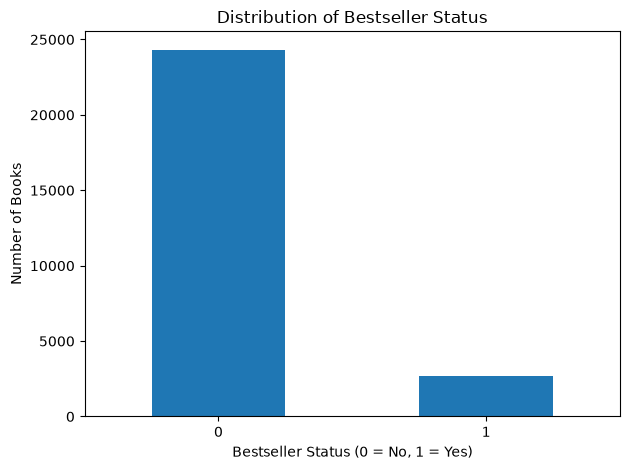

In [30]:
# ============================================================
# STEP 3B: CREATE THE BINARY TARGET VARIABLE
# ============================================================

# Calculate the 10th percentile of sales rank
rank_threshold = df[rank_column].quantile(0.10)

print("10th percentile sales rank:", rank_threshold)

# Retain records with a valid sales rank
df_model = df.dropna(subset=[rank_column]).copy()

# Bestseller = sales rank at or below the 10th percentile
df_model["bestseller"] = (
    df_model[rank_column] <= rank_threshold
).astype(int)

# Display target distribution
print("\nTarget variable distribution:")
print(df_model["bestseller"].value_counts())

print("\nTarget variable percentages:")
print(
    (df_model["bestseller"].value_counts(normalize=True) * 100)
    .round(2)
)

# Visualise the target distribution
df_model["bestseller"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Bestseller Status")
plt.xlabel("Bestseller Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# STEP 4: FEATURE SELECTION AND BASIC CLEANING
# ============================================================

selected_features = [
    "statistics.average rating",
    "statistics.sale price",
    "statistics.total reviews",
    "genre",
    "publisher.type",
    "sold by"
]

target = "bestseller"

# Create the modelling dataset
model_df = df_model[selected_features + [target]].copy()

# Convert numerical features to numeric
numeric_features = [
    "statistics.average rating",
    "statistics.sale price",
    "statistics.total reviews"
]

for column in numeric_features:
    model_df[column] = pd.to_numeric(
        model_df[column],
        errors="coerce"
    )

# Check missing values in the selected columns
print("Missing values in selected variables:")
print(model_df.isnull().sum())

print("\nModelling dataset shape:", model_df.shape)

display(model_df.head())

Missing values in selected variables:
statistics.average rating    0
statistics.sale price        0
statistics.total reviews     0
genre                        0
publisher.type               0
sold by                      0
bestseller                   0
dtype: int64

Modelling dataset shape: (27027, 7)


,statistics.average rating,statistics.sale price,statistics.total reviews,genre,publisher.type,sold by,bestseller
0,4.57,4.88,9604,genre fiction,big five,HarperCollins Publishers,1
1,4.47,1.99,450,genre fiction,big five,HarperCollins Publishers,1
2,4.16,8.69,30,genre fiction,small/medium,"Amazon Digital Services, Inc.",1
3,3.84,7.50,3747,fiction,big five,Hachette Book Group,1
4,4.75,7.99,9174,genre fiction,big five,Penguin Group (USA) LLC,1


In [35]:
# ============================================================
# RELOAD CSV WITH CORRECT COLUMN SEPARATION
# ============================================================

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

spark = SparkSession.builder \
    .appName("PublisherDataAnalysis") \
    .getOrCreate()

spark_df = (
    spark.read
    .format("csv")
    .option("header", "true")
    .option("inferSchema", "false")
    .option("sep", ",")
    .option("quote", '"')
    .option("escape", '"')
    .option("multiLine", "true")
    .load(file_path)
)

print("Number of columns:", len(spark_df.columns))
print("Column names:")

for column in spark_df.columns:
    print(repr(column))

spark_df.show(5, truncate=False)

Number of columns: 13
Column names:
'genre'
'sold by'
'daily average.amazon revenue'
'daily average.author revenue'
'daily average.gross sales'
'daily average.publisher revenue'
'daily average.units sold'
'publisher.name'
'publisher.type'
'statistics.average rating'
'statistics.sale price'
'statistics.sales rank'
'statistics.total reviews'
+-------------+------------------------------+----------------------------+----------------------------+-------------------------+-------------------------------+------------------------+---------------------------+--------------+-------------------------+---------------------+---------------------+------------------------+
|genre        |sold by                       |daily average.amazon revenue|daily average.author revenue|daily average.gross sales|daily average.publisher revenue|daily average.units sold|publisher.name             |publisher.type|statistics.average rating|statistics.sale price|statistics.sales rank|statistics.total reviews|
+-----

In [36]:
# ============================================================
# CELL 9: CREATE THE BINARY BESTSELLER TARGET
# ============================================================

from pyspark.sql import functions as F

# Verify that the sales-rank column exists
rank_column = "statistics.sales rank"

if rank_column not in spark_df.columns:
    raise ValueError(
        f"Column '{rank_column}' was not found.\n"
        f"Available columns: {spark_df.columns}"
    )

# Convert sales rank to a numeric column
spark_df = spark_df.withColumn(
    "sales_rank_numeric",
    F.regexp_replace(
        F.trim(F.col("`statistics.sales rank`")),
        ",",
        ""
    ).cast("double")
)

# Remove missing and non-positive sales ranks
target_df = spark_df.filter(
    F.col("sales_rank_numeric").isNotNull() &
    (F.col("sales_rank_numeric") > 0)
)

# Calculate the 10th percentile
quantiles = target_df.approxQuantile(
    "sales_rank_numeric",
    [0.10],
    0.001
)

if not quantiles:
    raise ValueError(
        "No valid numeric sales ranks were found. "
        "Check the sales-rank data."
    )

rank_threshold = quantiles[0]

print("10th-percentile sales-rank threshold:", rank_threshold)

# Create the binary target:
# 1 = Bestseller proxy (top 10% by numerical sales rank)
# 0 = Not in the top 10%

target_df = target_df.withColumn(
    "bestseller",
    F.when(
        F.col("sales_rank_numeric") <= rank_threshold,
        1
    ).otherwise(0)
)

# Count records in each class
print("\nBestseller class counts:")

target_df.groupBy("bestseller") \
    .count() \
    .orderBy("bestseller") \
    .show()

# Calculate total usable records
total_count = target_df.count()

# Calculate class percentages
print("\nBestseller class percentages:")

target_df.groupBy("bestseller").agg(
    F.count("*").alias("count"),
    F.round(
        F.count("*") / F.lit(total_count) * 100,
        2
    ).alias("percentage")
).orderBy("bestseller").show()

print("Total usable records:", total_count)

10th-percentile sales-rank threshold: 3590.0

Bestseller class counts:
+----------+-----+
|bestseller|count|
+----------+-----+
|         0|24343|
|         1| 2684|
+----------+-----+


Bestseller class percentages:
+----------+-----+----------+
|bestseller|count|percentage|
+----------+-----+----------+
|         0|24343|     90.07|
|         1| 2684|      9.93|
+----------+-----+----------+

Total usable records: 27027


In [37]:
# ============================================================
# RESTART SPARK SESSION
# ============================================================

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("BookBestsellerLogisticRegression")
    .master("local[2]")
    .config("spark.driver.memory", "2g")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark session created successfully.")
print("Spark version:", spark.version)

Spark session created successfully.
Spark version: 4.2.0


In [38]:
# ============================================================
# RELOAD CLEANED DATASET
# ============================================================

file_path = r"C:\Users\Francis Zulu\Documents\Postgraduate Diploma in Data Analytics - PDDA0801\S2\PDAN8412\Part 2\publishers_cleaned.csv"

spark_df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(file_path)
)

print("Dataset loaded successfully.")
print("Number of records:", spark_df.count())

spark_df.printSchema()

Dataset loaded successfully.
Number of records: 27027
root
 |-- genre: string (nullable = true)
 |-- sold by: string (nullable = true)
 |-- daily average.amazon revenue: double (nullable = true)
 |-- daily average.author revenue: double (nullable = true)
 |-- daily average.gross sales: double (nullable = true)
 |-- daily average.publisher revenue: double (nullable = true)
 |-- daily average.units sold: integer (nullable = true)
 |-- publisher.name: string (nullable = true)
 |-- publisher.type: string (nullable = true)
 |-- statistics.average rating: double (nullable = true)
 |-- statistics.sale price: double (nullable = true)
 |-- statistics.sales rank: integer (nullable = true)
 |-- statistics.total reviews: integer (nullable = true)



In [39]:
# ============================================================
# RECREATE BESTSELLER TARGET
# ============================================================

# Backticks protect the period in the original column name.
spark_df = spark_df.withColumn(
    "sales_rank_numeric",
    F.col("`statistics.sales rank`").cast("double")
)

target_df = spark_df.filter(
    F.col("sales_rank_numeric").isNotNull() &
    (F.col("sales_rank_numeric") > 0)
)

rank_threshold = target_df.approxQuantile(
    "sales_rank_numeric",
    [0.10],
    0.001
)[0]

target_df = target_df.withColumn(
    "bestseller",
    F.when(
        F.col("sales_rank_numeric") <= rank_threshold,
        1
    ).otherwise(0)
)

print("Sales rank threshold:", rank_threshold)
print("Usable records:", target_df.count())

target_df.groupBy("bestseller").count().show()

Sales rank threshold: 3590.0
Usable records: 27027
+----------+-----+
|bestseller|count|
+----------+-----+
|         1| 2684|
|         0|24343|
+----------+-----+



C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Valid book-price records: 27027
count    27027.000000
mean         6.777488
std          6.368486
min          0.010000
25%          2.990000
50%          5.120000
75%          9.990000
max        141.520000
Name: sale_price_numeric, dtype: float64


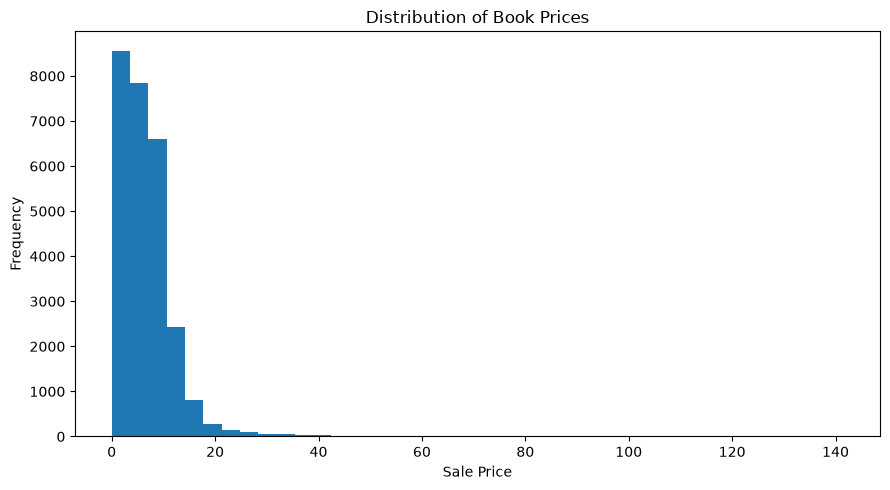

In [40]:
# ============================================================
# CELL 11: BOOK-PRICE DISTRIBUTION
# ============================================================

# Convert price to numeric and use a clean column name.
price_df = target_df.withColumn(
    "sale_price_numeric",
    F.col("`statistics.sale price`").cast("double")
)

# Keep valid, non-negative prices.
price_df = price_df.filter(
    F.col("sale_price_numeric").isNotNull() &
    (F.col("sale_price_numeric") >= 0)
)

# Collect only the required column.
price_data = price_df.select(
    "sale_price_numeric"
).toPandas()

print("Valid book-price records:", len(price_data))
print(price_data["sale_price_numeric"].describe())

# Plot the distribution.
plt.figure(figsize=(9, 5))

plt.hist(
    price_data["sale_price_numeric"],
    bins=40
)

plt.title("Distribution of Book Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Number of valid ratings: 27027
count    27027.000000
mean         4.159787
std          0.995815
min          0.000000
25%          4.080000
50%          4.400000
75%          4.640000
max          5.000000
Name: average_rating, dtype: float64


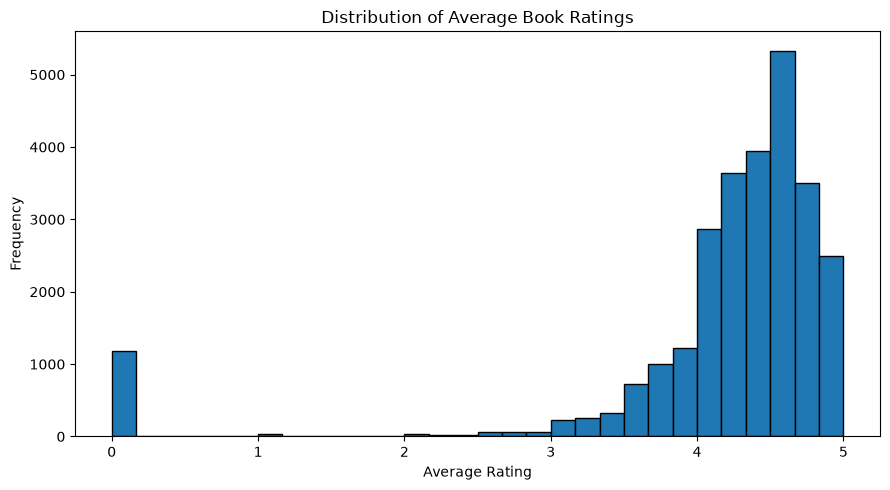

In [41]:
# ============================================================
# CELL 12: AVERAGE RATING DISTRIBUTION
# ============================================================

rating_data = (
    target_df
    .select(
        F.col("`statistics.average rating`")
        .cast("double")
        .alias("average_rating")
    )
    .filter(
        F.col("average_rating").isNotNull() &
        (F.col("average_rating") >= 0)
    )
    .toPandas()
)

print("Number of valid ratings:", len(rating_data))
print(rating_data["average_rating"].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    rating_data["average_rating"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


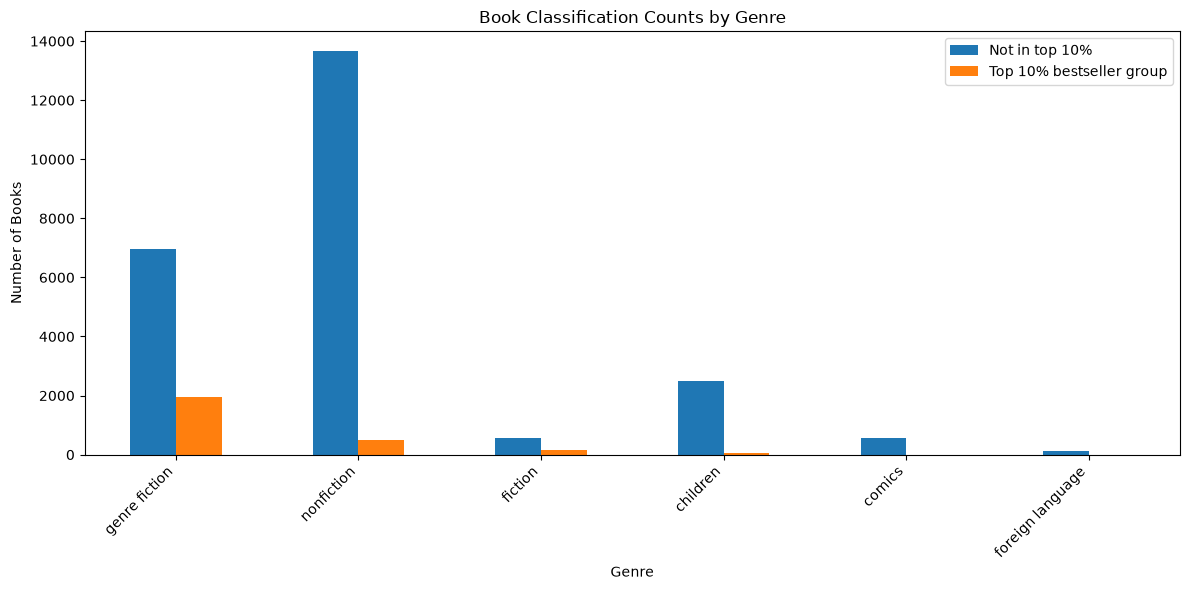

In [42]:
# ============================================================
# CELL 13: BESTSELLER DISTRIBUTION BY GENRE
# ============================================================

genre_summary = (
    target_df
    .filter(F.col("genre").isNotNull())
    .groupBy("genre", "bestseller")
    .count()
    .toPandas()
)

genre_pivot = genre_summary.pivot(
    index="genre",
    columns="bestseller",
    values="count"
).fillna(0)

genre_pivot.columns = [
    "Not in top 10%",
    "Top 10% bestseller group"
]

genre_pivot = genre_pivot.sort_values(
    "Top 10% bestseller group",
    ascending=False
)

genre_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Book Classification Counts by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Books")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [43]:
# ============================================================
# CELL 14: BESTSELLER RATE BY GENRE
# ============================================================

genre_rates = (
    target_df
    .filter(F.col("genre").isNotNull())
    .groupBy("genre")
    .agg(
        F.count("*").alias("total_books"),
        F.avg(
            F.col("bestseller").cast("double")
        ).alias("bestseller_rate")
    )
    .withColumn(
        "bestseller_percentage",
        F.round(F.col("bestseller_rate") * 100, 2)
    )
    .orderBy(
        F.col("bestseller_percentage").desc()
    )
)

genre_rates.show(truncate=False)

+----------------+-----------+---------------------+---------------------+
|genre           |total_books|bestseller_rate      |bestseller_percentage|
+----------------+-----------+---------------------+---------------------+
|genre fiction   |8903       |0.21936425923845895  |21.94                |
|fiction         |733        |0.21282401091405184  |21.28                |
|nonfiction      |14161      |0.036155638726078666 |3.62                 |
|children        |2541       |0.024006296733569462 |2.4                  |
|comics          |568        |0.0035211267605633804|0.35                 |
|foreign language|121        |0.0                  |0.0                  |
+----------------+-----------+---------------------+---------------------+



In [44]:
# ============================================================
# CELL 15: SELECT AND CLEAN MODELLING DATA
# ============================================================

from pyspark.sql import functions as F

# Clean numeric columns by removing stray double quotation marks.
# Invalid numeric values will become NULL rather than causing an error.

model_spark_df = target_df.select(
    F.regexp_replace(
        F.col("`statistics.average rating`").cast("string"),
        '"', ''
    ).cast("double").alias("average_rating"),

    F.regexp_replace(
        F.col("`statistics.sale price`").cast("string"),
        '"', ''
    ).cast("double").alias("sale_price"),

    F.regexp_replace(
        F.col("`statistics.total reviews`").cast("string"),
        '"', ''
    ).cast("double").alias("total_reviews"),

    F.col("genre").alias("genre"),
    F.col("`publisher.type`").alias("publisher_type"),
    F.col("`sold by`").alias("sold_by"),
    F.col("bestseller").cast("int").alias("bestseller")
)

# Convert the cleaned Spark DataFrame to Pandas.
model_df = model_spark_df.toPandas()

print("Modelling dataset shape:", model_df.shape)

print("\nFirst five rows:")
print(model_df.head())

print("\nData types:")
print(model_df.dtypes)

print("\nMissing values:")
print(model_df.isnull().sum())

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\pyspark\sql\pandas\conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Modelling dataset shape: (27027, 7)

First five rows:
   average_rating  sale_price  total_reviews          genre publisher_type  \
0            4.57        4.88         9604.0  genre fiction       big five   
1            4.47        1.99          450.0  genre fiction       big five   
2            4.16        8.69           30.0  genre fiction   small/medium   
3            3.84        7.50         3747.0        fiction       big five   
4            4.75        7.99         9174.0  genre fiction       big five   

                          sold_by  bestseller  
0        HarperCollins Publishers           1  
1        HarperCollins Publishers           1  
2  Amazon Digital Services,  Inc.           1  
3             Hachette Book Group           1  
4         Penguin Group (USA) LLC           1  

Data types:
average_rating    float64
sale_price        float64
total_reviews     float64
genre                 str
publisher_type        str
sold_by               str
bestseller          

In [45]:
# ============================================================
# CELL 16: DATA QUALITY CLEANING
# ============================================================

import numpy as np
import pandas as pd

# Replace infinite values with missing values.
model_df = model_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove duplicate rows from the selected modelling dataset.
before_duplicates = len(model_df)

model_df = model_df.drop_duplicates().copy()

after_duplicates = len(model_df)

print(
    "Duplicate rows removed:",
    before_duplicates - after_duplicates
)

# Remove rows with a missing target.
model_df = model_df.dropna(
    subset=["bestseller"]
).copy()

# Ensure the target is an integer.
model_df["bestseller"] = model_df["bestseller"].astype(int)

# Inspect missingness after cleaning.
print("\nRemaining missing values:")
print(model_df.isnull().sum())

print("\nTarget distribution:")
print(model_df["bestseller"].value_counts())

print("\nTarget distribution (percentages):")
print(
    (model_df["bestseller"].value_counts(normalize=True) * 100)
    .round(2)
)

Duplicate rows removed: 2592

Remaining missing values:
average_rating    0
sale_price        0
total_reviews     0
genre             0
publisher_type    0
sold_by           0
bestseller        0
dtype: int64

Target distribution:
bestseller
0    21838
1     2597
Name: count, dtype: int64

Target distribution (percentages):
bestseller
0    89.37
1    10.63
Name: proportion, dtype: float64


In [46]:
# ============================================================
# CELL 17: TRANSFORM REVIEW COUNTS
# ============================================================

# Ensure review counts are numeric and handle missing values.
model_df["total_reviews"] = pd.to_numeric(
    model_df["total_reviews"],
    errors="coerce"
)

# Replace negative review counts with zero before transformation.
model_df["log_reviews"] = np.log1p(
    model_df["total_reviews"].clip(lower=0)
)

# Remove the original review count because the transformed
# feature will be used in the logistic regression model.
model_df = model_df.drop(
    columns=["total_reviews"]
)

print("Summary statistics for transformed review counts:")
print(model_df[["log_reviews"]].describe())

print("\nUpdated modelling dataset columns:")
print(model_df.columns.tolist())

Summary statistics for transformed review counts:
        log_reviews
count  24435.000000
mean       3.820590
std        1.514906
min        0.000000
25%        2.833213
50%        3.806662
75%        4.820282
max       10.058909

Updated modelling dataset columns:
['average_rating', 'sale_price', 'genre', 'publisher_type', 'sold_by', 'bestseller', 'log_reviews']


In [47]:
# ============================================================
# CELL 18: DEFINE FEATURES AND TARGET
# ============================================================

# Define the predictors using the cleaned column names from Cell 15.
feature_columns = [
    "average_rating",
    "sale_price",
    "log_reviews",
    "genre",
    "publisher_type",
    "sold_by"
]

# Separate predictors (X) from the target variable (y).
X_raw = model_df[feature_columns].copy()

y = model_df["bestseller"].astype(int).to_numpy()

print("Number of observations:", len(y))
print("Number of predictors before encoding:", len(feature_columns))

print("\nTarget classes:")
print(pd.Series(y).value_counts())

print("\nFeature columns:")
print(X_raw.columns.tolist())

Number of observations: 24435
Number of predictors before encoding: 6

Target classes:
0    21838
1     2597
Name: count, dtype: int64

Feature columns:
['average_rating', 'sale_price', 'log_reviews', 'genre', 'publisher_type', 'sold_by']


In [48]:
# ============================================================
# CELL 19: STRATIFIED TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Set a reproducible random state if it has not already been defined.
try:
    RANDOM_STATE
except NameError:
    RANDOM_STATE = 42

# Split the data into training (80%) and testing (20%) sets.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(y_train))
print("Testing observations:", len(y_test))

print(
    "Training bestseller proportion:",
    round(y_train.mean(), 4)
)

print(
    "Testing bestseller proportion:",
    round(y_test.mean(), 4)
)

Training observations: 19548
Testing observations: 4887
Training bestseller proportion: 0.1063
Testing bestseller proportion: 0.1062


In [49]:
# ============================================================
# CELL 20: PREPARE NUMERICAL FEATURES
# ============================================================

import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Use the cleaned column names created in Cell 15.
numerical_features = [
    "average_rating",
    "sale_price",
    "log_reviews"
]

# Convert numerical columns explicitly.
for column in numerical_features:
    X_train_raw[column] = pd.to_numeric(
        X_train_raw[column],
        errors="coerce"
    )

    X_test_raw[column] = pd.to_numeric(
        X_test_raw[column],
        errors="coerce"
    )

# Learn imputation values from training data only.
imputer = SimpleImputer(strategy="median")

X_train_num = imputer.fit_transform(
    X_train_raw[numerical_features]
)

X_test_num = imputer.transform(
    X_test_raw[numerical_features]
)

# Learn scaling parameters from training data only.
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

print("Numerical training shape:", X_train_num.shape)
print("Numerical testing shape:", X_test_num.shape)

print("\nNumerical features:", numerical_features)
print("Missing values handled using training-set medians.")
print("Numerical features standardised successfully.")

Numerical training shape: (19548, 3)
Numerical testing shape: (4887, 3)

Numerical features: ['average_rating', 'sale_price', 'log_reviews']
Missing values handled using training-set medians.
Numerical features standardised successfully.


In [50]:
# ============================================================
# CELL 21: ENCODE CATEGORICAL FEATURES
# ============================================================

categorical_features = [
    "genre",
    "publisher_type",
    "sold_by"
]

X_train_cat_raw = (
    X_train_raw[categorical_features]
    .fillna("Unknown")
    .astype(str)
)

X_test_cat_raw = (
    X_test_raw[categorical_features]
    .fillna("Unknown")
    .astype(str)
)

# One-hot encode training categories.
X_train_cat_df = pd.get_dummies(
    X_train_cat_raw,
    columns=categorical_features,
    dtype=float
)

# One-hot encode test categories.
X_test_cat_df = pd.get_dummies(
    X_test_cat_raw,
    columns=categorical_features,
    dtype=float
)

# Align the test columns with the training columns.
X_test_cat_df = X_test_cat_df.reindex(
    columns=X_train_cat_df.columns,
    fill_value=0
)

X_train_cat = X_train_cat_df.to_numpy(dtype=float)
X_test_cat = X_test_cat_df.to_numpy(dtype=float)

print("Categorical training shape:", X_train_cat.shape)
print("Categorical testing shape:", X_test_cat.shape)

Categorical training shape: (19548, 25)
Categorical testing shape: (4887, 25)


In [51]:
# ============================================================
# CELL 22: COMBINE NUMERICAL AND CATEGORICAL FEATURES
# ============================================================

X_train = np.hstack([
    X_train_num,
    X_train_cat
])

X_test = np.hstack([
    X_test_num,
    X_test_cat
])

# Check that all features are finite.
if not np.isfinite(X_train).all():
    raise ValueError("Training features contain non-finite values.")

if not np.isfinite(X_test).all():
    raise ValueError("Testing features contain non-finite values.")

print("Final training feature matrix:", X_train.shape)
print("Final testing feature matrix:", X_test.shape)
print("Training target vector:", y_train.shape)
print("Testing target vector:", y_test.shape)

Final training feature matrix: (19548, 28)
Final testing feature matrix: (4887, 28)
Training target vector: (19548,)
Testing target vector: (4887,)


In [53]:
# ============================================================
# CELL 23: LOGISTIC REGRESSION FROM SCRATCH
# ============================================================

class LogisticRegressionScratch:
    """
    Binary logistic regression implemented using NumPy.

    Parameters
    ----------
    learning_rate : float
        Step size used by gradient descent.

    epochs : int
        Number of gradient-descent iterations.

    l2 : float
        L2 regularisation strength.
    """

    def __init__(
        self,
        learning_rate=0.01,
        epochs=2000,
        l2=0.01
    ):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2

        self.weights = None
        self.bias = None
        self.loss_history = []

    def sigmoid(self, z):
        """
        Convert a linear score into a probability.

        Clipping prevents numerical overflow in exp().
        """
        z = np.clip(z, -500, 500)

        return 1 / (1 + np.exp(-z))

    def compute_loss(self, y, probabilities):
        """
        Calculate binary cross-entropy plus L2 regularisation.
        """
        epsilon = 1e-12

        probabilities = np.clip(
            probabilities,
            epsilon,
            1 - epsilon
        )

        binary_cross_entropy = -np.mean(
            y * np.log(probabilities)
            + (1 - y) * np.log(1 - probabilities)
        )

        regularisation = (
            self.l2
            / (2 * len(y))
            * np.sum(self.weights ** 2)
        )

        return binary_cross_entropy + regularisation

    def fit(self, X, y):
        """
        Train the model using gradient descent.
        """

        n_samples, n_features = X.shape

        # Initialise coefficients and intercept.
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        self.loss_history = []

        # Repeatedly update the model parameters.
        for epoch in range(self.epochs):

            # Step 1: Calculate linear scores.
            linear_scores = X @ self.weights + self.bias

            # Step 2: Convert scores to probabilities.
            probabilities = self.sigmoid(linear_scores)

            # Step 3: Calculate the gradients.
            error = probabilities - y

            dw = (
                X.T @ error
            ) / n_samples

            # Add the L2 regularisation gradient.
            dw += (
                self.l2 / n_samples
            ) * self.weights

            db = np.mean(error)

            # Step 4: Update the coefficients.
            self.weights -= (
                self.learning_rate * dw
            )

            # Step 5: Update the intercept.
            self.bias -= (
                self.learning_rate * db
            )

            # Step 6: Record the loss.
            if epoch % 10 == 0 or epoch == self.epochs - 1:

                updated_scores = (
                    X @ self.weights + self.bias
                )

                updated_probabilities = self.sigmoid(
                    updated_scores
                )

                loss = self.compute_loss(
                    y,
                    updated_probabilities
                )

                self.loss_history.append(loss)

        return self

    def predict_proba(self, X):
        """
        Return probabilities for the positive class.
        """

        linear_scores = X @ self.weights + self.bias

        probabilities = self.sigmoid(linear_scores)

        return np.column_stack([
            1 - probabilities,
            probabilities
        ])

    def predict(self, X, threshold=0.5):
        """
        Convert probabilities into binary class predictions.
        """

        probabilities = self.predict_proba(X)[:, 1]

        return (
            probabilities >= threshold
        ).astype(int)


In [54]:
# ============================================================
# CELL 24: TRAIN THE INITIAL MODEL
# ============================================================

initial_model = LogisticRegressionScratch(
    learning_rate=0.01,
    epochs=2000,
    l2=0.01
)

initial_model.fit(
    X_train,
    y_train
)

print("Initial model trained successfully.")
print("Number of coefficients:", len(initial_model.weights))
print("Intercept:", initial_model.bias)

Initial model trained successfully.
Number of coefficients: 28
Intercept: -1.1024914630001756


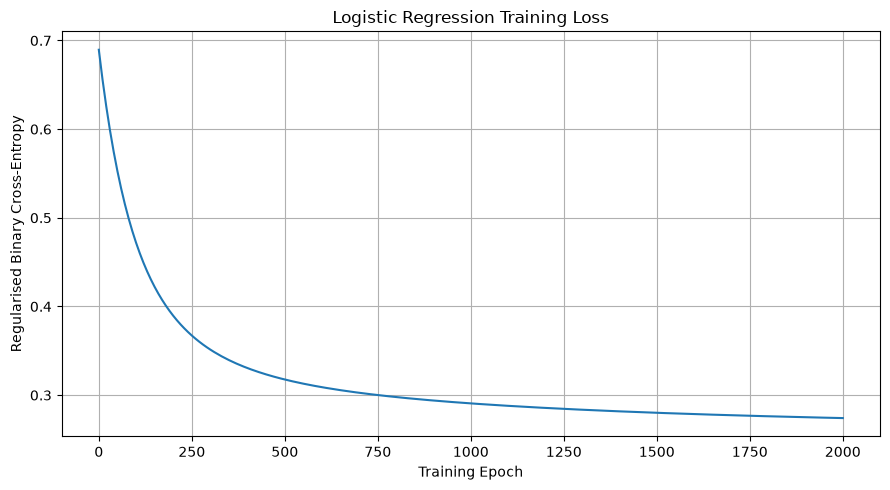

In [55]:
# ============================================================
# CELL 25: PLOT TRAINING LOSS
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(len(initial_model.loss_history)) * 10,
    initial_model.loss_history
)

plt.title("Logistic Regression Training Loss")
plt.xlabel("Training Epoch")
plt.ylabel("Regularised Binary Cross-Entropy")
plt.grid(True)

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# CELL 26: GENERATE INITIAL TEST PREDICTIONS
# ============================================================

y_probability_initial = (
    initial_model.predict_proba(X_test)[:, 1]
)

y_pred_initial = initial_model.predict(
    X_test,
    threshold=0.5
)

print("First ten predicted probabilities:")
print(y_probability_initial[:10])

print("\nFirst ten predicted classes:")
print(y_pred_initial[:10])

First ten predicted probabilities:
[0.02577484 0.17847806 0.25692468 0.07129614 0.07226214 0.16771141
 0.04216943 0.0982401  0.14130843 0.19173486]

First ten predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [57]:
# ============================================================
# CELL 27: INITIAL MODEL EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    log_loss
)

def evaluate_classifier(y_true, y_pred, y_probability):
    """
    Calculate and return classification metrics.
    """

    metrics = {
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1-score": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "Balanced accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "ROC-AUC": roc_auc_score(
            y_true, y_probability
        ),

        "Log loss": log_loss(
            y_true,
            np.column_stack([
                1 - y_probability,
                y_probability
            ]),
            labels=[0, 1]
        )
    }

    return metrics


# Evaluate the initial model.
initial_metrics = evaluate_classifier(
    y_test,
    y_pred_initial,
    y_probability_initial
)

# Display the results.
initial_results = pd.DataFrame(
    initial_metrics.items(),
    columns=["Metric", "Initial Model"]
)

print(initial_results.to_string(index=False))

           Metric  Initial Model
         Accuracy       0.898711
        Precision       1.000000
           Recall       0.046243
         F1-score       0.088398
Balanced accuracy       0.523121
          ROC-AUC       0.827195
         Log loss       0.268840


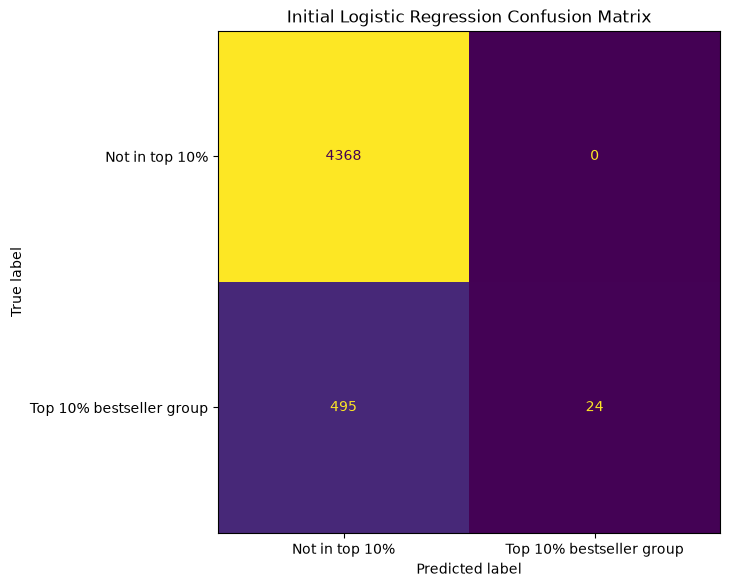

In [58]:
# ============================================================
# CELL 28: CONFUSION MATRIX
# ============================================================

# Import required libraries
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_initial,
    labels=[0, 1]
)

# Create the confusion matrix display
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not in top 10%",
        "Top 10% bestseller group"
    ]
)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

cm_display.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title("Initial Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

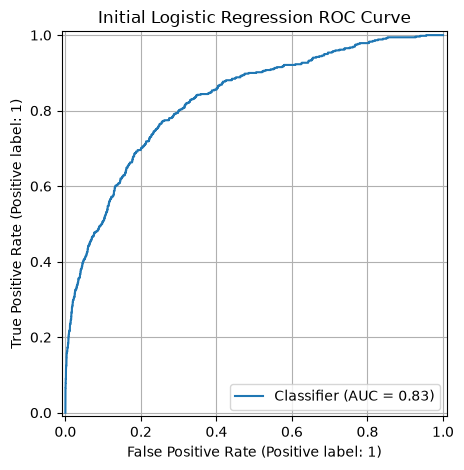

In [59]:
# ============================================================
# CELL 29: ROC CURVE
# ============================================================

# Import required libraries
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Plot the ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    y_probability_initial
)

plt.title("Initial Logistic Regression ROC Curve")
plt.grid(True)
plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# CELL 30: EXAMINE MODEL COEFFICIENTS
# ============================================================

feature_names = (
    numerical_features
    + list(X_train_cat_df.columns)
)

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": initial_model.weights
})

coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print(
    coefficient_table[
        ["Feature", "Coefficient"]
    ].to_string(index=False)
)

                                     Feature  Coefficient
                            genre_nonfiction    -0.851709
      sold_by_Amazon Digital Services,  Inc.    -0.652883
                                 log_reviews     0.578363
                 publisher_type_small/medium    -0.502440
                     publisher_type_big five    -0.429089
                                  sale_price    -0.309169
                              genre_children    -0.297232
                publisher_type_single author    -0.207291
                    sold_by_Random House LLC    -0.144627
                         genre_genre fiction     0.116707
            sold_by_HarperCollins Publishers    -0.083956
sold_by_Simon and Schuster Digital Sales Inc    -0.079217
             sold_by_Penguin Group (USA) LLC    -0.064080
                                genre_comics    -0.062607
                           sold_by_Macmillan    -0.048314
                              average_rating    -0.041695
              

In [61]:
# ============================================================
# CELL 31: CALCULATE ODDS RATIOS
# ============================================================

coefficient_table["Odds_Ratio"] = np.exp(
    coefficient_table["Coefficient"].clip(-50, 50)
)

print(
    coefficient_table[
        ["Feature", "Coefficient", "Odds_Ratio"]
    ].to_string(index=False)
)

                                     Feature  Coefficient  Odds_Ratio
                            genre_nonfiction    -0.851709    0.426685
      sold_by_Amazon Digital Services,  Inc.    -0.652883    0.520543
                                 log_reviews     0.578363    1.783117
                 publisher_type_small/medium    -0.502440    0.605052
                     publisher_type_big five    -0.429089    0.651102
                                  sale_price    -0.309169    0.734057
                              genre_children    -0.297232    0.742872
                publisher_type_single author    -0.207291    0.812783
                    sold_by_Random House LLC    -0.144627    0.865345
                         genre_genre fiction     0.116707    1.123790
            sold_by_HarperCollins Publishers    -0.083956    0.919471
sold_by_Simon and Schuster Digital Sales Inc    -0.079217    0.923839
             sold_by_Penguin Group (USA) LLC    -0.064080    0.937930
                    

In [ ]:
%pip install statsmodels

In [62]:
# Check which training variables are available
variables_to_check = [
    "X_train",
    "X_train_num",
    "X_train_raw",
    "X_train_encoded",
    "y_train"
]

for var_name in variables_to_check:
    print(f"{var_name}: {var_name in globals()}")

X_train: True
X_train_num: True
X_train_raw: True
X_train_encoded: False
y_train: True


In [63]:
# ============================================================
# CHECK TRAINING VARIABLES
# ============================================================

variables_to_check = [
    "model_df",
    "X_raw",
    "X_train_raw",
    "X_train_num",
    "y_train",
    "y_test",
    "y_pred_initial",
    "y_probability_initial"
]

for var_name in variables_to_check:
    print(f"{var_name}: {var_name in globals()}")

model_df: True
X_raw: True
X_train_raw: True
X_train_num: True
y_train: True
y_test: True
y_pred_initial: True
y_probability_initial: True


In [65]:
# Check whether the custom logistic regression class is defined

print("LogisticRegressionScratch" in globals())

True


In [67]:
# ============================================================
# RESTORE: LOGISTIC REGRESSION FROM SCRATCH
# ============================================================

import numpy as np

class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.01, epochs=1000, l2=0.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def sigmoid(self, z):
        # Clip values to avoid numerical overflow
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)

        if X.ndim != 2:
            raise ValueError("X must be a two-dimensional feature matrix.")

        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of rows.")

        if not np.isfinite(X).all():
            raise ValueError("X contains missing or infinite values.")

        if not np.isfinite(y).all():
            raise ValueError("y contains missing or infinite values.")

        if not np.isin(y, [0, 1]).all():
            raise ValueError("The target y must contain only 0 and 1.")

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):

            # Forward propagation
            linear_output = np.dot(X, self.weights) + self.bias
            probabilities = self.sigmoid(linear_output)

            # Calculate gradients
            errors = probabilities - y

            dw = (np.dot(X.T, errors) / n_samples)
            dw += (self.l2 / n_samples) * self.weights

            db = np.mean(errors)

            # Update weights and bias
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

            # Record loss
            probabilities_clipped = np.clip(
                probabilities, 1e-15, 1 - 1e-15
            )

            loss = -np.mean(
                y * np.log(probabilities_clipped)
                + (1 - y) * np.log(1 - probabilities_clipped)
            )

            loss += (self.l2 / (2 * n_samples)) * np.sum(self.weights ** 2)

            self.loss_history.append(loss)

        return self

    def predict_proba(self, X):
        if self.weights is None:
            raise ValueError("The model must be fitted before prediction.")

        X = np.asarray(X, dtype=float)

        probabilities = self.sigmoid(
            np.dot(X, self.weights) + self.bias
        )

        return probabilities

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

In [68]:
print("LogisticRegressionScratch" in globals())

True


In [69]:
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())

X_train: True
y_train: True


In [70]:
# ============================================================
# DIAGNOSTIC: CHECK AVAILABLE DATA VARIABLES
# ============================================================

variables_to_check = [
    "model_spark_df",
    "model_df",
    "X_raw",
    "y",
    "X_train_raw",
    "X_test_raw",
    "y_train",
    "y_test",
    "X_train_num",
    "X_test_num",
    "X_train",
    "X_test"
]

for var_name in variables_to_check:
    print(f"{var_name}: {var_name in globals()}")

model_spark_df: True
model_df: True
X_raw: True
y: True
X_train_raw: True
X_test_raw: True
y_train: True
y_test: True
X_train_num: True
X_test_num: True
X_train: True
X_test: True


In [71]:
# Check that training data is available

print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())

if "X_train" in globals() and "y_train" in globals():
    print("Training feature shape:", X_train.shape)
    print("Training target shape:", y_train.shape)

X_train exists: True
y_train exists: True
Training feature shape: (19548, 28)
Training target shape: (19548,)


In [72]:
# ============================================================
# DIAGNOSTIC: IDENTIFY THE LAST AVAILABLE DATA PREPARATION STAGE
# ============================================================

variables_to_check = [
    "model_spark_df",
    "model_df",
    "X_raw",
    "y",
    "X_train_raw",
    "X_test_raw",
    "y_train",
    "y_test",
    "X_train_num",
    "X_test_num",
    "X_train_cat",
    "X_test_cat",
    "X_train_encoded",
    "X_test_encoded",
    "initial_model",
    "improved_model"
]

for var_name in variables_to_check:
    exists = var_name in globals()
    print(f"{var_name}: {exists}")

model_spark_df: True
model_df: True
X_raw: True
y: True
X_train_raw: True
X_test_raw: True
y_train: True
y_test: True
X_train_num: True
X_test_num: True
X_train_cat: True
X_test_cat: True
X_train_encoded: False
X_test_encoded: False
initial_model: True
improved_model: False


In [73]:
# ============================================================
# CELL 32: OPTIONAL STATISTICAL FEATURE DIAGNOSTICS
# ============================================================

import statsmodels.api as sm

# Use the already prepared training feature matrix.
X_train_inference = sm.add_constant(
    X_train,
    has_constant="add"
)

# Fit a conventional logistic regression for inference.
inference_model = sm.Logit(
    y_train,
    X_train_inference
)

inference_result = inference_model.fit(
    disp=False,
    maxiter=200
)

print(inference_result.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                19548
Model:                          Logit   Df Residuals:                    19522
Method:                           MLE   Df Model:                           25
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.2421
Time:                        14:35:47   Log-Likelihood:                -5018.2
converged:                      False   LL-Null:                       -6621.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.6472        nan        nan        nan         nan         nan
x1            -0.0650      0.041     -1.589      0.112      -0.145       0.015
x2            -0.8443      0.071    -11.854      0.0

C:\Users\Francis Zulu\anaconda3\envs\lstm_assignment\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [74]:
# ============================================================
# CELL 33: TRAIN THE IMPROVED MODEL
# ============================================================

improved_model = LogisticRegressionScratch(
    learning_rate=0.005,
    epochs=3000,
    l2=0.10
)

improved_model.fit(
    X_train,
    y_train
)

print("Improved model trained successfully.")

Improved model trained successfully.


In [76]:
# ============================================================
# CELL 34: EVALUATE THE IMPROVED MODEL
# ============================================================

import numpy as np
import pandas as pd

# Get predicted probabilities
y_probability_improved = np.asarray(
    improved_model.predict_proba(X_test)
).reshape(-1)

# Get predicted classes
y_pred_improved = improved_model.predict(
    X_test,
    threshold=0.5
)

# Evaluate the improved model
improved_metrics = evaluate_classifier(
    y_test,
    y_pred_improved,
    y_probability_improved
)

# Compare initial and improved models
comparison = pd.DataFrame({
    "Metric": list(initial_metrics.keys()),
    "Initial Model": list(initial_metrics.values()),
    "Improved Model": list(improved_metrics.values())
})

print("\nMODEL PERFORMANCE COMPARISON")
print("=" * 60)
print(comparison.to_string(index=False))


MODEL PERFORMANCE COMPARISON
           Metric  Initial Model  Improved Model
         Accuracy       0.898711        0.896051
        Precision       1.000000        1.000000
           Recall       0.046243        0.021195
         F1-score       0.088398        0.041509
Balanced accuracy       0.523121        0.510597
          ROC-AUC       0.827195        0.823160
         Log loss       0.268840        0.274964


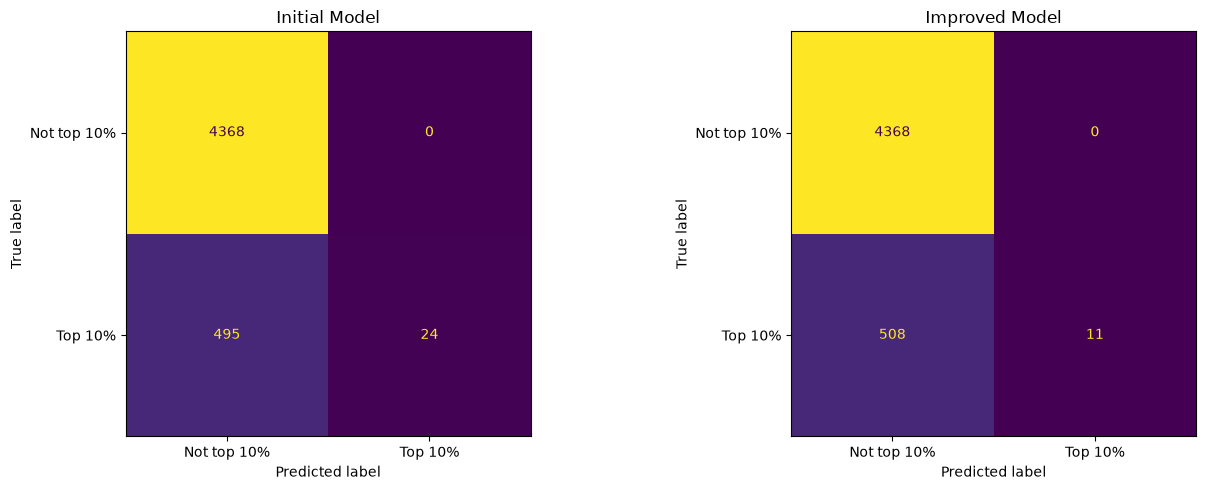

In [77]:
# ============================================================
# CELL 35: COMPARE INITIAL AND IMPROVED CONFUSION MATRICES
# ============================================================

cm_initial = confusion_matrix(
    y_test,
    y_pred_initial,
    labels=[0, 1]
)

cm_improved = confusion_matrix(
    y_test,
    y_pred_improved,
    labels=[0, 1]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_initial,
    display_labels=["Not top 10%", "Top 10%"]
).plot(
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Initial Model")

ConfusionMatrixDisplay(
    confusion_matrix=cm_improved,
    display_labels=["Not top 10%", "Top 10%"]
).plot(
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Improved Model")

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# CELL 36: REFERENCE MODEL FOR VALIDATION
# ============================================================

reference_model = ReferenceLogisticRegression(
    max_iter=2000,
    C=1.0,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

reference_model.fit(
    X_train,
    y_train
)

reference_probabilities = (
    reference_model.predict_proba(X_test)[:, 1]
)

reference_predictions = reference_model.predict(
    X_test
)

reference_metrics = evaluate_classifier(
    y_test,
    reference_predictions,
    reference_probabilities
)

reference_comparison = pd.DataFrame({
    "Metric": list(initial_metrics.keys()),
    "From-Scratch Model": list(initial_metrics.values()),
    "Scikit-learn Reference": list(reference_metrics.values())
})

print(reference_comparison.to_string(index=False))

           Metric  From-Scratch Model  Scikit-learn Reference
         Accuracy            0.898711                0.906487
        Precision            1.000000                0.715278
           Recall            0.046243                0.198459
         F1-score            0.088398                0.310709
Balanced accuracy            0.523121                0.594536
          ROC-AUC            0.827195                0.846841
         Log loss            0.268840                0.251345
